In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.pyplot import figure
import math
from haversine import haversine, Unit
from datetime import datetime, timedelta
from sklearn.metrics import silhouette_score

In [3]:
df = pd.read_csv("C:/Users/chene/Documents/MasterAbschlussArbeit/Data/df_5.csv").drop(columns=['Unnamed: 0'])

In [10]:
df["UTC"] = pd.to_datetime(df["UTC"])

In [13]:
df["UTC"].max()

Timestamp('2024-09-30 23:55:51+0000', tz='UTC')

Text(0.5, 1.0, 'Distribution of AIS points with the progression of time.')

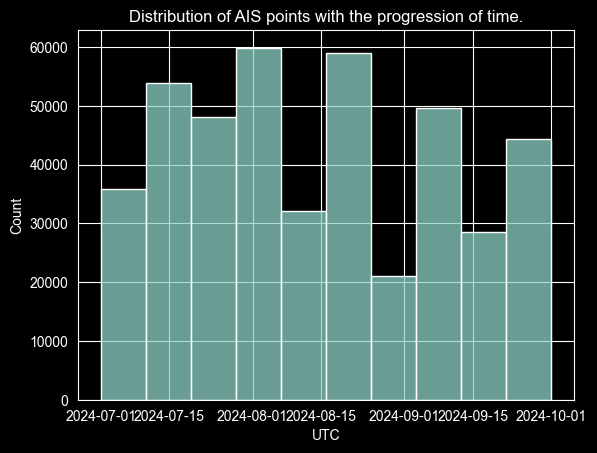

In [19]:
sns.histplot(df["UTC"], bins=10)
plt.title("Distribution of AIS points with the progression of time.")

In [41]:
training_cut_off_point = "2024-09-01"
val_cut_off_point = "2024-09-16"

In [42]:
df = df.sort_values(by=["trajectory_ID", "UTC"], ascending=[True, True])
training = df[df["UTC"]<training_cut_off_point]
val = df[(df["UTC"]>=training_cut_off_point) & (df["UTC"]<val_cut_off_point)]
test = df[df["UTC"]>=val_cut_off_point]

In [43]:
print(f"Trajectories points before {training_cut_off_point} go to training dataset. There are {len(training)} AIS trajectory points in training dataset, accounting for {round(len(training)/len(df)*100, 4)}% of the data. \n"
      f"Trajectories points before {val_cut_off_point} go to validation dataset. There are {len(val)} AIS trajectory points in validation dataset, accounting for {round(len(val)/len(df)*100,2)}% of the data. \n"
      f"Trajectories points on or after {val_cut_off_point} go to testing dataset. There are {len(test)} AIS trajectory points in test dataset, accounting for {round(len(test)/len(df)*100,2)}% of the data.")

Trajectories points before 2024-09-01 go to training dataset. There are 304088 AIS trajectory points in training dataset, accounting for 70.3507% of the data. 
Trajectories points before 2024-09-16 go to validation dataset. There are 65303 AIS trajectory points in validation dataset, accounting for 15.11% of the data. 
Trajectories points on or after 2024-09-16 go to testing dataset. There are 62855 AIS trajectory points in test dataset, accounting for 14.54% of the data.


In [45]:
for name, d in [("training", training), ("validation", val), ("test", test)]:
    d.to_csv(f"C:/Users/chene/Documents/MasterAbschlussArbeit/Data/LSTM_2_try/{name}.csv")